# AE4 · Métricas, gráficos y respuestas de negocio

Este notebook construye las métricas y visualizaciones que sirven de base a la aplicación Streamlit de AE4. El análisis retoma las preguntas del proyecto sobre los salarios reportados en empleos de datos y tecnología. Es descriptivo y se limita a los registros disponibles; no representa una organización específica.

## Preguntas
1. ¿Cómo se comparan los salarios en USD por nivel de experiencia, modalidad de trabajo y tamaño de empresa?
2. ¿Cuántos registros hay por año de referencia, nivel de experiencia y tipo de empleo?
3. ¿Qué cargos tienen más registros y cuál es su salario mediano en USD?
4. ¿Cómo cambia el salario mediano en USD entre los años cubiertos?

Las tablas se guardan en `src/AE3/resultados/` con los nombres que consume `src/AE4/app.py`. El notebook parte de los CSV preparados por AE3; ejecuta primero `src/AE3/Semana_3_AE3.ipynb` si todavía no existen.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Encuentra la raíz del proyecto aunque Jupyter se inicie desde otra carpeta.
candidatos = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in candidatos if (p / "src" / "AE3").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encontró src/AE3. Inicia Jupyter dentro del repositorio.")

DIR_AE3 = ROOT / "src" / "AE3"
RUTA_PREPARADO = DIR_AE3 / "datos" / "demo-salaries-preparado.csv"
RUTA_ORIGINAL = DIR_AE3 / "datos" / "demo-salaries-original.csv"
DIR_RESULTADOS = DIR_AE3 / "resultados"
COLUMNAS_ORIGINALES = [
    "work_year", "experience_level", "employment_type", "job_title", "salary",
    "salary_currency", "salary_in_usd", "employee_residence", "remote_ratio",
    "company_location", "company_size",
]
ORDEN_EXPERIENCIA = ["Inicial", "Intermedio", "Senior", "Ejecutivo"]
ORDEN_MODALIDAD = ["Presencial", "Híbrido", "Remoto"]
ORDEN_TAMANO = ["Pequeña", "Mediana", "Grande"]
ORDEN_EMPLEO = ["Tiempo completo", "Tiempo parcial", "Contrato", "Freelance"]

if not RUTA_PREPARADO.is_file() or not RUTA_ORIGINAL.is_file():
    raise FileNotFoundError("Faltan los CSV de AE3; ejecuta primero el notebook de AE3.")
df = pd.read_csv(RUTA_PREPARADO, encoding="utf-8-sig")
df_original = pd.read_csv(RUTA_ORIGINAL, encoding="utf-8-sig")
requeridas = set(COLUMNAS_ORIGINALES + ["remote_work_mode"])
faltantes = requeridas - set(df.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en el dataset preparado: {sorted(faltantes)}")
if df["salary_in_usd"].isna().any() or (df["salary_in_usd"] < 0).any():
    raise ValueError("salary_in_usd contiene valores faltantes o negativos.")

periodo = f"{int(df['work_year'].min())}–{int(df['work_year'].max())}"
n_repetidas = int(df.duplicated(subset=COLUMNAS_ORIGINALES).sum())
display(Markdown(
    f"**Datos cargados:** {len(df):,} registros, {df['job_title'].nunique():,} cargos, "
    f"años de referencia {periodo}, {int(df.isna().sum().sum()):,} valores nulos en el "
    f"dataset preparado y {n_repetidas:,} filas repetidas exactas "
    f"({n_repetidas / len(df):.1%}). Se conservan las repeticiones en el análisis principal."
))

**Datos cargados:** 3,755 registros, 93 cargos, años de referencia 2020–2023, 0 valores nulos en el dataset preparado y 1,171 filas repetidas exactas (31.2%). Se conservan las repeticiones en el análisis principal.

## Criterios de lectura

- `salary_in_usd` es un salario reportado convertido a dólares. El conjunto no especifica su periodicidad; por eso la unidad se reporta como **USD (periodicidad no especificada)**, no como sueldo mensual o anual.
- Una fila es un registro, no necesariamente una persona única: no hay identificador de persona o empresa. Las filas idénticas se conservan para no asumir que sean errores; su efecto se muestra en una comparación de sensibilidad.
- Los conteos describen la composición de esta muestra. Un cargo frecuente no implica que tenga mayor salario, y un salario no es ingreso ni rentabilidad de una empresa.
- Las diferencias entre grupos o años no prueban causalidad. País, cargo, experiencia y composición de la muestra pueden variar conjuntamente.

## 1. Salario por experiencia, modalidad y tamaño de empresa

**Métrica y cálculo:** para cada combinación de nivel de experiencia × modalidad × tamaño de empresa, se calcula el número de registros (*n*), la mediana de `salary_in_usd` y los cuartiles Q1 y Q3 (percentiles 25 y 75). La mediana es el valor central al ordenar los salarios; Q1–Q3 muestra el 50 % central. **Unidad:** conteos en registros y salarios en USD con periodicidad no especificada.

**Gráfico:** barras de la mediana con intervalos Q1–Q3, separadas por tamaño de empresa y coloreadas por modalidad. Permite comparar el centro y la dispersión central entre grupos. Para facilitar la lectura se muestran grupos con al menos 10 registros; la tabla completa conserva todos los grupos.

**Decisión que podría apoyar:** orientar qué segmentos conviene estudiar con mayor detalle antes de diseñar rangos de compensación. No permite fijar ofertas sin información adicional de país, cargo, beneficios y periodicidad.

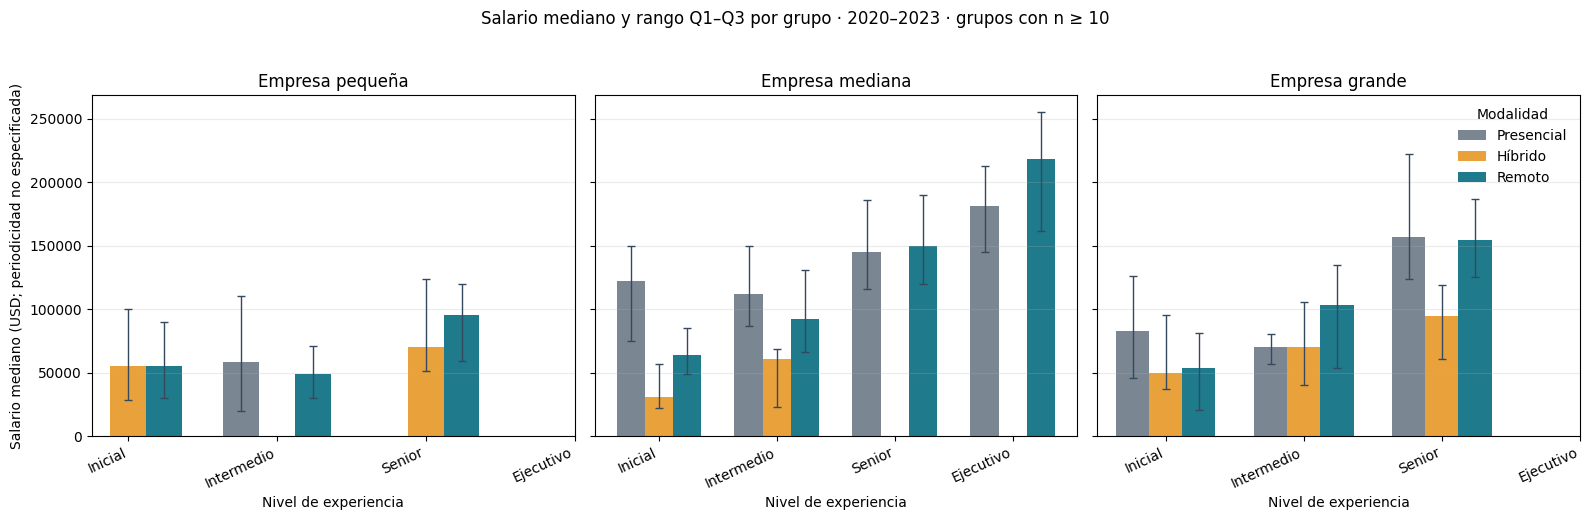

**Respuesta e interpretación:** la mediana más alta entre niveles es **Ejecutivo** (USD 196,000) y la más baja es **Inicial** (USD 70,000). Las diferencias por modalidad y tamaño son descriptivas y pueden reflejar mezclas distintas de cargo, país y experiencia; no prueban que esas características causen los salarios observados. Una decisión de compensación requiere segmentar y validar esos factores, además de confirmar la periodicidad.

,experience_level,remote_work_mode,company_size,cantidad_registros,salario_usd_mediana,salario_usd_promedio,salario_usd_q1,salario_usd_q3
29,Senior,Presencial,Mediana,1269,145000.0,152596.0,115440.0,185900.0
32,Senior,Remoto,Mediana,989,150000.0,155486.0,120000.0,190000.0
20,Intermedio,Presencial,Mediana,367,112000.0,120497.0,86596.0,150000.0
23,Intermedio,Remoto,Mediana,238,92350.0,101164.0,66608.0,130600.0
31,Senior,Remoto,Grande,95,154600.0,153499.0,125000.0,186500.0
11,Inicial,Presencial,Mediana,86,122117.0,111749.0,74540.0,150000.0
28,Senior,Presencial,Grande,86,156800.0,174424.0,123700.0,222200.0
22,Intermedio,Remoto,Grande,69,103000.0,100283.0,53416.0,135000.0
14,Inicial,Remoto,Mediana,63,64200.0,69788.0,49253.0,85000.0
3,Ejecutivo,Presencial,Mediana,52,181080.0,185279.0,145000.0,212500.0


In [2]:
tabla_principal = (
    df.groupby(["experience_level", "remote_work_mode", "company_size"], observed=True)
    .agg(
        cantidad_registros=("salary_in_usd", "size"),
        salario_usd_mediana=("salary_in_usd", "median"),
        salario_usd_promedio=("salary_in_usd", "mean"),
        salario_usd_q1=("salary_in_usd", lambda v: v.quantile(0.25)),
        salario_usd_q3=("salary_in_usd", lambda v: v.quantile(0.75)),
    )
    .reset_index()
)
if int(tabla_principal["cantidad_registros"].sum()) != len(df):
    raise ValueError("La tabla principal no contabiliza todos los registros.")

fig, axes = plt.subplots(1, len(ORDEN_TAMANO), figsize=(16, 5), sharey=True)
colores = {"Presencial": "#7a8793", "Híbrido": "#e9a23b", "Remoto": "#1f7a8c"}
x = np.arange(len(ORDEN_EXPERIENCIA))
ancho = 0.24
for ax, tamano in zip(axes, ORDEN_TAMANO):
    subset = tabla_principal[
        (tabla_principal["company_size"] == tamano)
        & (tabla_principal["cantidad_registros"] >= 10)
    ]
    for j, modalidad in enumerate(ORDEN_MODALIDAD):
        s = subset[subset["remote_work_mode"] == modalidad].set_index("experience_level")
        s = s.reindex(ORDEN_EXPERIENCIA).dropna(subset=["salario_usd_mediana"])
        posiciones = x[[ORDEN_EXPERIENCIA.index(nivel) for nivel in s.index]] + (j - 1) * ancho
        mediana = s["salario_usd_mediana"].to_numpy()
        abajo = mediana - s["salario_usd_q1"].to_numpy()
        arriba = s["salario_usd_q3"].to_numpy() - mediana
        ax.bar(posiciones, mediana, width=ancho, color=colores[modalidad], label=modalidad)
        ax.errorbar(posiciones, mediana, yerr=np.vstack([abajo, arriba]),
                    fmt="none", ecolor="#34495e", capsize=3, linewidth=1)
    ax.set_title(f"Empresa {tamano.lower()}")
    ax.set_xticks(x, ORDEN_EXPERIENCIA, rotation=25, ha="right")
    ax.set_xlabel("Nivel de experiencia")
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Salario mediano (USD; periodicidad no especificada)")
axes[-1].legend(title="Modalidad", frameon=False)
fig.suptitle(f"Salario mediano y rango Q1–Q3 por grupo · {periodo} · grupos con n ≥ 10", y=1.03)
fig.tight_layout()
plt.show()

medianas_experiencia = df.groupby("experience_level", observed=True)["salary_in_usd"].median()
nivel_menor = medianas_experiencia.idxmin()
nivel_mayor = medianas_experiencia.idxmax()
display(Markdown(
    f"**Respuesta e interpretación:** la mediana más alta entre niveles es **{nivel_mayor}** "
    f"(USD {medianas_experiencia[nivel_mayor]:,.0f}) y la más baja es **{nivel_menor}** "
    f"(USD {medianas_experiencia[nivel_menor]:,.0f}). Las diferencias por modalidad y tamaño "
    "son descriptivas y pueden reflejar mezclas distintas de cargo, país y experiencia; no prueban "
    "que esas características causen los salarios observados. Una decisión de compensación requiere "
    "segmentar y validar esos factores, además de confirmar la periodicidad."
))
display(tabla_principal.sort_values("cantidad_registros", ascending=False).head(10).round(0))

## 2. Cantidad de registros por año, experiencia y tipo de empleo

**Métrica y cálculo:** número de filas (`count` de registros) para cada combinación de `work_year`, nivel de experiencia y tipo de empleo. **Unidad:** registros; `work_year` es año de referencia, no fecha exacta de pago.

**Gráfico:** paneles por nivel de experiencia; cada barra corresponde a un año y se apila por tipo de empleo. Facilita ver simultáneamente el tamaño de los grupos y su composición.

**Decisión que podría apoyar:** identificar segmentos con pocas observaciones que requieren cautela o más datos antes de compararlos. El volumen observado no mide demanda laboral del mercado.

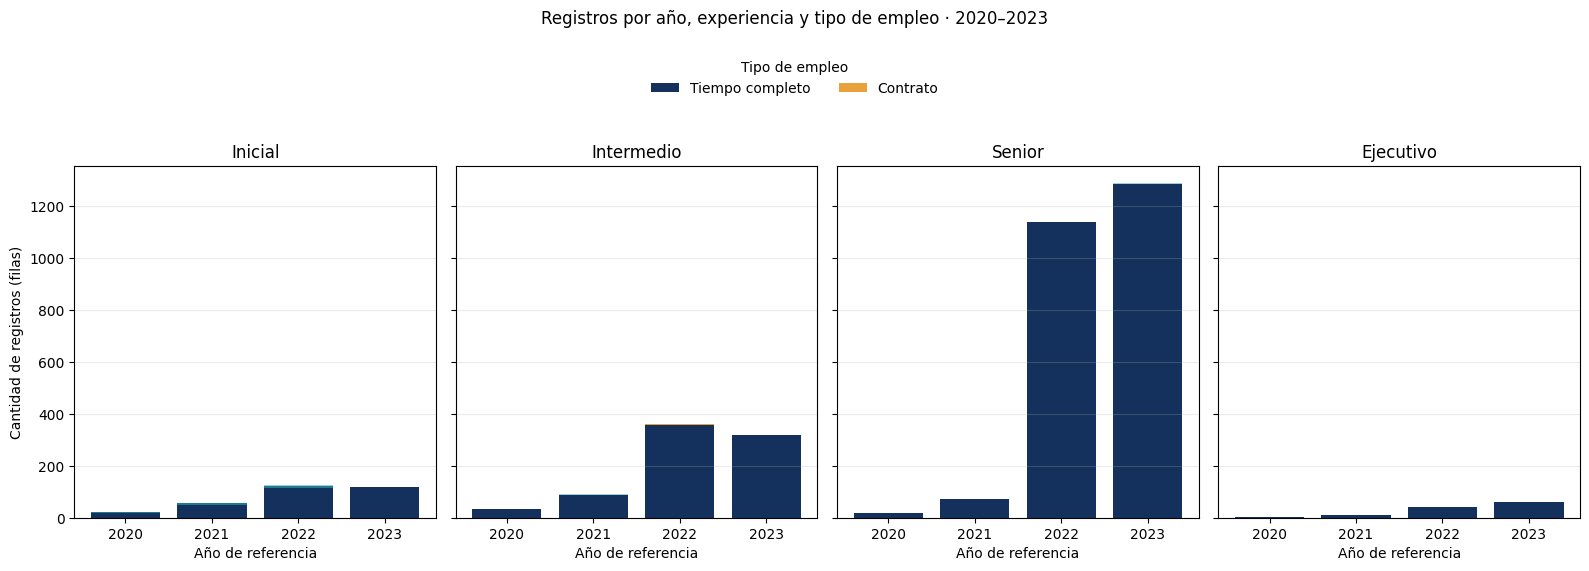

**Respuesta e interpretación:** el año con más registros es **2023** (1,785 filas). El gráfico permite observar cómo se reparte ese volumen por experiencia y tipo de empleo. Los conteos sirven para juzgar la cobertura de cada comparación, no para concluir que aumentó o disminuyó el empleo en el mercado.

,work_year,experience_level,employment_type,cantidad_registros
0,2020,Ejecutivo,Tiempo completo,3
1,2020,Inicial,Contrato,1
2,2020,Inicial,Tiempo completo,20
3,2020,Inicial,Tiempo parcial,2
4,2020,Intermedio,Tiempo completo,32
5,2020,Senior,Freelance,1
6,2020,Senior,Tiempo completo,17
7,2021,Ejecutivo,Contrato,1
8,2021,Ejecutivo,Tiempo completo,9
9,2021,Inicial,Tiempo completo,50


In [3]:
tabla_apoyo_1 = (
    df.groupby(["work_year", "experience_level", "employment_type"], observed=True)
    .size().reset_index(name="cantidad_registros")
)
anios = sorted(df["work_year"].unique())
fig, axes = plt.subplots(1, len(ORDEN_EXPERIENCIA), figsize=(16, 4.8), sharey=True)
colores_empleo = dict(zip(ORDEN_EMPLEO, ["#13315c", "#1f7a8c", "#e9a23b", "#9ccfe0"]))
for ax, experiencia in zip(axes, ORDEN_EXPERIENCIA):
    s = tabla_apoyo_1[tabla_apoyo_1["experience_level"] == experiencia]
    pivote = (s.pivot(index="work_year", columns="employment_type", values="cantidad_registros")
              .reindex(index=anios, columns=ORDEN_EMPLEO).fillna(0))
    base = np.zeros(len(pivote))
    for empleo in ORDEN_EMPLEO:
        valores = pivote[empleo].to_numpy()
        if valores.sum() > 0:
            ax.bar(pivote.index.astype(str), valores, bottom=base,
                   color=colores_empleo[empleo], label=empleo)
            base += valores
    ax.set_title(experiencia)
    ax.set_xlabel("Año de referencia")
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Cantidad de registros (filas)")
handles, labels = axes[-1].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, title="Tipo de empleo", loc="upper center",
               bbox_to_anchor=(0.5, 1.10), ncol=4, frameon=False)
fig.suptitle(f"Registros por año, experiencia y tipo de empleo · {periodo}", y=1.18)
fig.tight_layout()
plt.show()

conteo_anual = tabla_apoyo_1.groupby("work_year")["cantidad_registros"].sum()
anio_mayor = int(conteo_anual.idxmax())
display(Markdown(
    f"**Respuesta e interpretación:** el año con más registros es **{anio_mayor}** "
    f"({int(conteo_anual[anio_mayor]):,} filas). El gráfico permite observar cómo se reparte "
    "ese volumen por experiencia y tipo de empleo. Los conteos sirven para juzgar la cobertura "
    "de cada comparación, no para concluir que aumentó o disminuyó el empleo en el mercado."
))
display(tabla_apoyo_1.sort_values(["work_year", "experience_level", "employment_type"]).head(15))

## 3. Cargos con más registros y su salario mediano

**Métricas y cálculo:** por cargo, el número de filas y la mediana de `salary_in_usd`. Se seleccionan los 15 cargos con más registros (desempate alfabético). **Unidades:** registros y USD con periodicidad no especificada.

**Gráfico:** dos paneles horizontales con el mismo orden de cargos, uno para el conteo y otro para la mediana. Se muestran por separado para no confundir frecuencia con nivel salarial.

**Decisión que podría apoyar:** priorizar qué cargos estudiar al diseñar un análisis de mercado o al recolectar más datos. Que un cargo tenga muchos registros no demuestra que sea el más demandado, mejor pagado o más rentable.

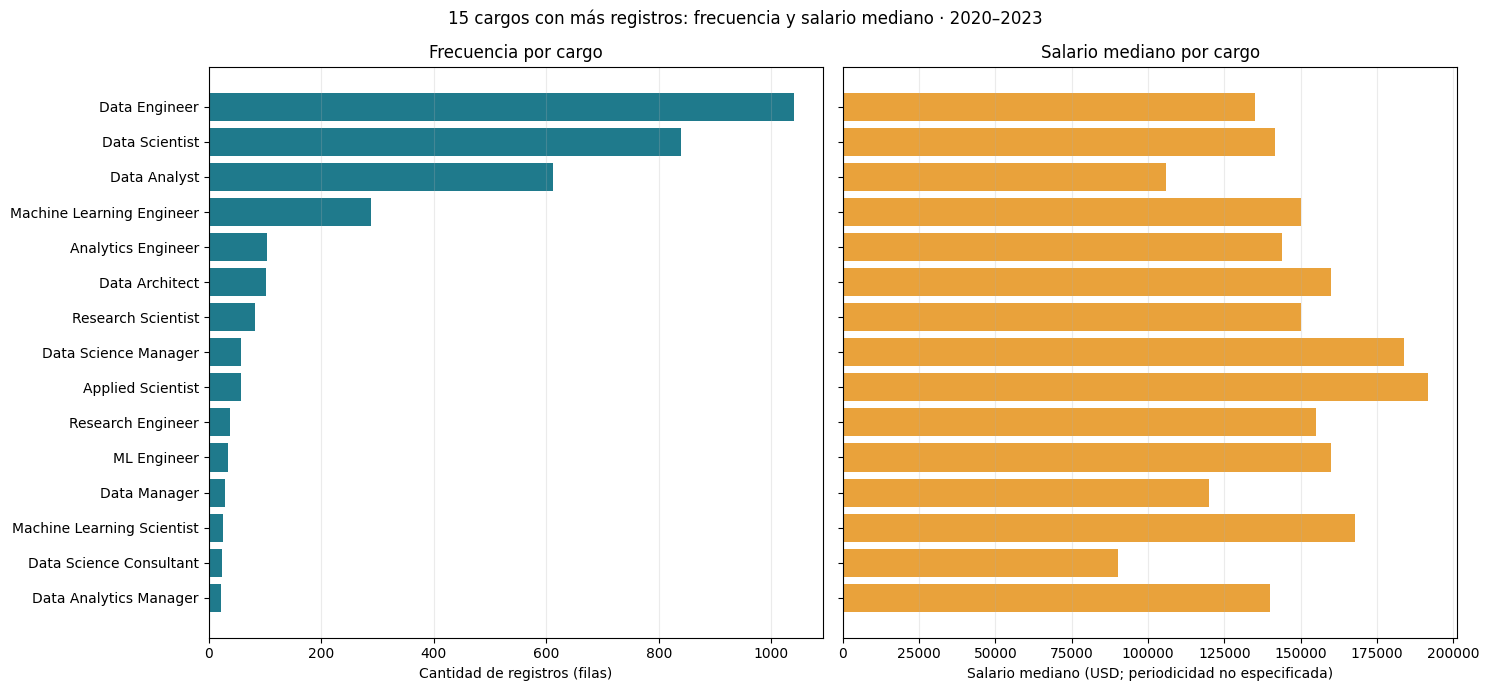

**Respuesta e interpretación:** el cargo con más registros es **Data Engineer** (1,040; mediana USD 135,000). Entre todos los cargos, la mediana más alta corresponde a **Data Science Tech Lead** (USD 375,000; n = 1). Frecuencia y mediana responden preguntas distintas; para decidir se debe considerar el tamaño de cada grupo y validar la periodicidad, el país y la experiencia.

,job_title,cantidad_registros,salario_usd_mediana
0,Data Engineer,1040,135000.0
1,Data Scientist,840,141525.0
2,Data Analyst,612,106020.0
3,Machine Learning Engineer,289,150000.0
4,Analytics Engineer,103,143860.0
5,Data Architect,101,160000.0
6,Research Scientist,82,150000.0
7,Applied Scientist,58,191738.0
8,Data Science Manager,58,183780.0
9,Research Engineer,37,155000.0


In [4]:
tabla_apoyo_2 = (
    df.groupby("job_title", observed=True)
    .agg(cantidad_registros=("salary_in_usd", "size"),
         salario_usd_mediana=("salary_in_usd", "median"))
    .reset_index()
    .sort_values(["cantidad_registros", "job_title"], ascending=[False, True])
    .reset_index(drop=True)
)
top_15 = tabla_apoyo_2.head(15).sort_values("cantidad_registros")
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
axes[0].barh(top_15["job_title"], top_15["cantidad_registros"], color="#1f7a8c")
axes[0].set_xlabel("Cantidad de registros (filas)")
axes[0].set_title("Frecuencia por cargo")
axes[1].barh(top_15["job_title"], top_15["salario_usd_mediana"], color="#e9a23b")
axes[1].set_xlabel("Salario mediano (USD; periodicidad no especificada)")
axes[1].set_title("Salario mediano por cargo")
for ax in axes:
    ax.grid(axis="x", alpha=0.25)
fig.suptitle(f"15 cargos con más registros: frecuencia y salario mediano · {periodo}")
fig.tight_layout()
plt.show()

cargo_frecuente = tabla_apoyo_2.iloc[0]
cargo_mediana_alta = tabla_apoyo_2.loc[tabla_apoyo_2["salario_usd_mediana"].idxmax()]
display(Markdown(
    f"**Respuesta e interpretación:** el cargo con más registros es **{cargo_frecuente['job_title']}** "
    f"({int(cargo_frecuente['cantidad_registros']):,}; mediana USD "
    f"{cargo_frecuente['salario_usd_mediana']:,.0f}). Entre todos los cargos, la mediana más alta "
    f"corresponde a **{cargo_mediana_alta['job_title']}** (USD "
    f"{cargo_mediana_alta['salario_usd_mediana']:,.0f}; n = "
    f"{int(cargo_mediana_alta['cantidad_registros']):,}). Frecuencia y mediana responden preguntas "
    "distintas; para decidir se debe considerar el tamaño de cada grupo y validar la periodicidad, "
    "el país y la experiencia."
))
display(tabla_apoyo_2.head(15).round(0))

## 4. Cambio del salario mediano entre años

**Métricas y cálculo:** mediana de `salary_in_usd` y cantidad de filas para cada `work_year`. Cambio absoluto = mediana del año actual − mediana del año anterior (USD); cambio porcentual = cambio absoluto ÷ mediana anterior × 100. El primer año no tiene comparación y queda sin cambio (*NaN*). **Unidades:** USD con periodicidad no especificada, porcentaje y registros.

**Gráfico:** línea para la mediana y panel separado de barras para el tamaño de muestra anual; permite leer el valor salarial junto al volumen que lo respalda.

**Decisión que podría apoyar:** identificar años que merecen investigación adicional sobre la composición de cargos, experiencia y países. Los cambios no prueban una tendencia del mercado ni su causa.

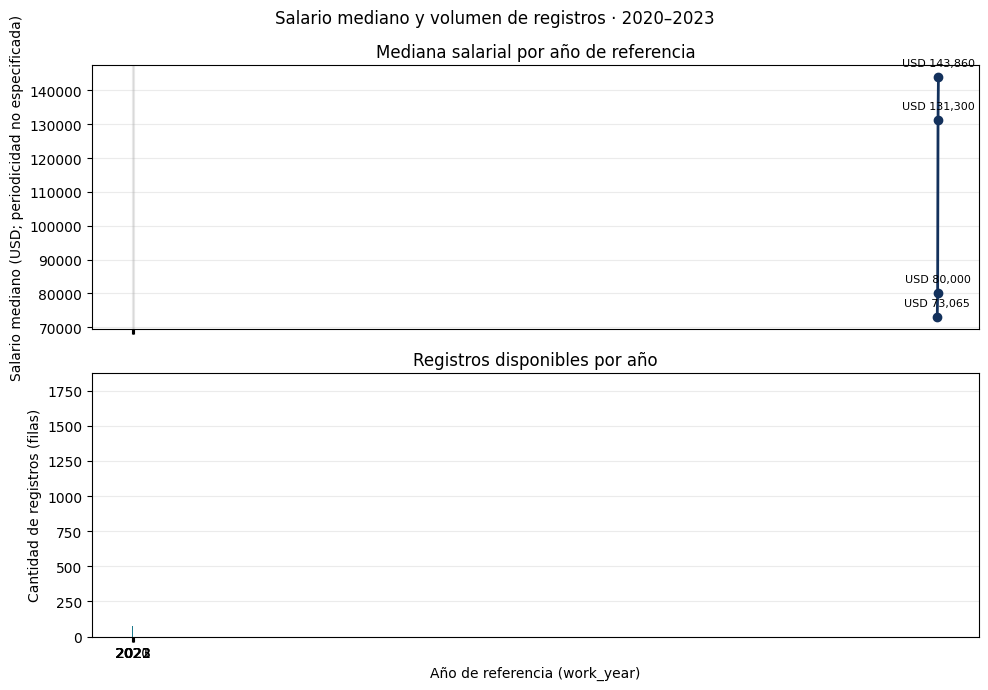

**Respuesta e interpretación:** entre 2020 y 2023, la mediana pasó de USD 73,065 a USD 143,860 (diferencia observada: USD +70,795). El tamaño de muestra también varía entre años, por lo que la serie puede reflejar cambios en su composición. No demuestra una causa ni equivale a una medición de inflación o de salarios para una población constante.

,work_year,cantidad_registros,salario_usd_mediano,variacion_mediana_usd_vs_anio_anterior,variacion_mediana_porcentual_vs_anio_anterior
0,2020,76,73065.0,NaN,NaN
1,2021,230,80000.0,6935.0,9.49
2,2022,1664,131300.0,51300.0,64.13
3,2023,1785,143860.0,12560.0,9.57


In [5]:
tabla_apoyo_3 = (
    df.groupby("work_year", observed=True)
    .agg(cantidad_registros=("salary_in_usd", "size"),
         salario_usd_mediano=("salary_in_usd", "median"))
    .reset_index()
    .sort_values("work_year")
    .reset_index(drop=True)
)
tabla_apoyo_3["variacion_mediana_usd_vs_anio_anterior"] = tabla_apoyo_3["salario_usd_mediano"].diff()
tabla_apoyo_3["variacion_mediana_porcentual_vs_anio_anterior"] = (
    tabla_apoyo_3["salario_usd_mediano"].pct_change() * 100
)
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(tabla_apoyo_3["work_year"], tabla_apoyo_3["salario_usd_mediano"],
             marker="o", color="#13315c", linewidth=2)
axes[0].set_ylabel("Salario mediano (USD; periodicidad no especificada)")
axes[0].set_title("Mediana salarial por año de referencia")
axes[0].grid(alpha=0.25)
for fila in tabla_apoyo_3.itertuples():
    axes[0].annotate(f"USD {fila.salario_usd_mediano:,.0f}",
                     (fila.work_year, fila.salario_usd_mediano),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
axes[1].bar(tabla_apoyo_3["work_year"].astype(str), tabla_apoyo_3["cantidad_registros"],
            color="#1f7a8c")
axes[1].set_xlabel("Año de referencia (work_year)")
axes[1].set_ylabel("Cantidad de registros (filas)")
axes[1].set_title("Registros disponibles por año")
axes[1].grid(axis="y", alpha=0.25)
fig.suptitle(f"Salario mediano y volumen de registros · {periodo}")
fig.tight_layout()
plt.show()

primero = tabla_apoyo_3.iloc[0]
ultimo = tabla_apoyo_3.iloc[-1]
cambio_total = ultimo["salario_usd_mediano"] - primero["salario_usd_mediano"]
display(Markdown(
    f"**Respuesta e interpretación:** entre {int(primero['work_year'])} y "
    f"{int(ultimo['work_year'])}, la mediana pasó de USD {primero['salario_usd_mediano']:,.0f} "
    f"a USD {ultimo['salario_usd_mediano']:,.0f} (diferencia observada: "
    f"USD {cambio_total:+,.0f}). El tamaño de muestra también varía entre años, por lo que la "
    "serie puede reflejar cambios en su composición. No demuestra una causa ni equivale a una "
    "medición de inflación o de salarios para una población constante."
))
display(tabla_apoyo_3.round(2))

## Limitaciones y uso responsable

- El dataset no identifica de forma única personas o empresas; las **filas exactamente repetidas se conservan** en los resultados principales y se compara la sensibilidad al excluirlas. Una repetición no prueba por sí sola que haya un error.
- `work_year` es un año de referencia. No hay fecha exacta de pago y la periodicidad de `salary_in_usd` no está especificada.
- Son salarios reportados, **no ingresos ni rentabilidad**; tampoco miden productividad, costos, beneficios ni demanda laboral total.
- Los resultados son asociaciones descriptivas dentro de estos datos. No permiten atribuir causalidad ni generalizar automáticamente a todo el mercado.
- Para tomar decisiones hacen falta contexto y validación adicionales: país/costo de vida, cargo, sector, experiencia, beneficios, fuente, periodo y calidad de los registros.

In [6]:
def resumir_version(nombre, datos):
    duplicados = int(datos.duplicated().sum())
    return {
        "version": nombre,
        "filas": len(datos),
        "columnas": len(datos.columns),
        "duplicados_exactos": duplicados,
        "porcentaje_duplicados_exactos": round(duplicados / len(datos) * 100, 2),
        "valores_nulos": int(datos.isna().sum().sum()),
        "salario_usd_promedio": round(float(datos["salary_in_usd"].mean()), 2),
        "salario_usd_mediana": float(datos["salary_in_usd"].median()),
    }

df_sin_repetidas = df.drop_duplicates(subset=COLUMNAS_ORIGINALES)
comparacion = pd.DataFrame([
    resumir_version("Original", df_original),
    resumir_version("Preparado; duplicados conservados", df),
    resumir_version("Sensibilidad; sin duplicados exactos", df_sin_repetidas),
])

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
tablas = {
    "pregunta_principal_salarios_por_grupo": tabla_principal,
    "pregunta_apoyo_1_registros_por_anio_experiencia_empleo": tabla_apoyo_1,
    "pregunta_apoyo_2_cargos_por_registros_y_mediana": tabla_apoyo_2,
    "pregunta_apoyo_3_salario_mediano_por_anio": tabla_apoyo_3,
    "comparacion_antes_despues": comparacion,
}
for nombre, tabla in tablas.items():
    ruta = DIR_RESULTADOS / f"{nombre}.csv"
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig")
    print(f"Generado: {ruta.relative_to(ROOT)} ({len(tabla)} filas)")

display(Markdown(
    "**Integración con Streamlit:** los cinco CSV anteriores se escribieron en la carpeta de "
    "resultados que lee `src/AE4/app.py`. El dataset preparado y los archivos fuente de AE3 "
    "no se modificaron. La tabla de sensibilidad permite valorar cómo influyen las filas "
    "repetidas en las métricas agregadas."
))
display(comparacion.round(2))

Generado: src\AE3\resultados\pregunta_principal_salarios_por_grupo.csv (34 filas)
Generado: src\AE3\resultados\pregunta_apoyo_1_registros_por_anio_experiencia_empleo.csv (35 filas)
Generado: src\AE3\resultados\pregunta_apoyo_2_cargos_por_registros_y_mediana.csv (93 filas)
Generado: src\AE3\resultados\pregunta_apoyo_3_salario_mediano_por_anio.csv (4 filas)
Generado: src\AE3\resultados\comparacion_antes_despues.csv (3 filas)


**Integración con Streamlit:** los cinco CSV anteriores se escribieron en la carpeta de resultados que lee `src/AE4/app.py`. El dataset preparado y los archivos fuente de AE3 no se modificaron. La tabla de sensibilidad permite valorar cómo influyen las filas repetidas en las métricas agregadas.

,version,filas,columnas,duplicados_exactos,porcentaje_duplicados_exactos,valores_nulos,salario_usd_promedio,salario_usd_mediana
0,Original,3755,11,1171,31.19,0,137570.39,135000.0
1,Preparado; duplicados conservados,3755,16,1171,31.19,0,137570.39,135000.0
2,Sensibilidad; sin duplicados exactos,2584,16,0,0.00,0,133409.28,130000.0
